# 04 · Avaliando o sistema inteiro: um conjunto de avaliação sobre OEE

> **Capítulo 4 do livro:** *Evaluate AI Systems*.
> No capítulo 3 vimos as **medidas**. Agora vem o **método**: critérios, conjunto de avaliação, estatística, escolha de modelo e uma rotina que impede regressões.

**Objetivo:** montar do zero um conjunto de avaliação para um assistente que responde perguntas sobre OEE, com gabarito calculado por código, e usá-lo para comparar sistemas, achar os erros e decidir qual (ou qual combinação) vai para a fábrica.

## Antes de começar

- **Você precisa saber:** OEE = disponibilidade × desempenho × qualidade, e os notebooks 02 e 03.
- **Você não precisa de:** chave de API. Os três sistemas são locais; um deles é **simulado** (comportamento parecido com o de um modelo, com falhas conhecidas) e está marcado assim. No capítulo 6 ele vira um modelo de verdade, avaliado com **este mesmo conjunto**.
- **Tempo:** 60 minutos.

## Mapa do notebook

1. Critérios: o que "bom" quer dizer para este assistente
2. O conjunto de avaliação, com gabarito calculado
3. Medir os três sistemas, por tipo de pergunta
4. Análise de erros
5. Quantas perguntas bastam?
6. Avaliar o próprio conjunto de avaliação
7. Escolher: precisão, custo e combinação de sistemas
8. Uma rotina que impede regressões

In [1]:
import sys, pathlib, random
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
%matplotlib inline
import matplotlib.pyplot as plt

## 1. Critérios: o que "bom" quer dizer para este assistente

Imagine um assistente que o supervisor de turno consulta: "qual foi o OEE da prensa ontem?". Antes de medir, escreva **o que** vai medir. Quatro famílias de critérios cobrem a maior parte dos sistemas:

| Família | Pergunta | Como medimos aqui |
|---|---|---|
| **Capacidade no domínio** | o número está certo? | valor igual ao gabarito calculado (com tolerância no OEE) |
| **Seguir instruções** | respondeu só o valor, como pedido? | formato da resposta |
| **Não inventar** | quando não há dado, ele diz que não há? | perguntas "armadilha" sobre dias sem dados |
| **Custo e latência** | quanto custa e quanto demora? | tokens por pergunta e preço por mil perguntas |

Cada critério precisa de **uma medida que um programa consiga calcular** e de um **limite de aceitação** definido antes de olhar os resultados. Por exemplo: "OEE com erro de até 0,5 ponto percentual conta como certo; a armadilha precisa passar de 90 %". Limites escolhidos depois do resultado tendem a justificar o que já se queria.

## 2. O conjunto de avaliação, com gabarito calculado

Uma planta sintética: 6 máquinas, 14 dias, 3 turnos por dia. Cada linha tem tempo planejado, tempo de falha, outras paradas, peças e defeitos.

In [2]:
from aiind.oeeqa import make_data, build_questions, factors, DAYS, IDEAL
from aiind.corpus import MACHINES
data = make_data()
print(len(data), "linhas (máquina × dia × turno). Exemplo:")
for r in data[:3]:
    print("  ", r)
f = factors(data, "prensa", 3)
print("\nprensa, dia 3:", {k: round(v, 3) for k, v in f.items()})

252 linhas (máquina × dia × turno). Exemplo:
   {'machine': 'enchedora', 'day': 1, 'shift': 1, 'planned': 360, 'failure': 0, 'other': 0, 'run': 360, 'total': 6734, 'defects': 380}
   {'machine': 'enchedora', 'day': 1, 'shift': 2, 'planned': 480, 'failure': 0, 'other': 10, 'run': 470, 'total': 6877, 'defects': 262}
   {'machine': 'enchedora', 'day': 1, 'shift': 3, 'planned': 480, 'failure': 0, 'other': 10, 'run': 470, 'total': 6614, 'defects': 152}

prensa, dia 3: {'disponibilidade': 0.889, 'desempenho': 0.878, 'qualidade': 0.963, 'oee': 0.751}


O OEE do dia usa **tempos e peças somados**: tempo bom ideal ÷ tempo planejado. Agora as perguntas. Elas saem de modelos de frase, com **três jeitos de perguntar** cada uma, e o **gabarito é calculado pelo mesmo código dos dados**, sem ninguém anotar à mão:

In [3]:
from collections import Counter
qs = build_questions(data, 300)
for q in qs[:6]:
    print(f"[{q.kind:8s} {q.difficulty:9s}] {q.text}\n    gabarito: {q.gold}")
print("\nperguntas por tipo:", dict(Counter(q.kind for q in qs)))
print("textos distintos:", len({q.text for q in qs}), "de", len(qs))

[falha    fácil    ] Quanto tempo de falha a prensa teve no dia 12, em minutos?
    gabarito: 0
[pior     difícil  ] No dia 13, qual máquina teve o pior OEE?
    gabarito: esteira
[perda    difícil  ] Maior perda de OEE da tampadora no 9º dia: disponibilidade, desempenho ou qualidade?
    gabarito: desempenho
[pecas    fácil    ] Peças boas da enchedora no 6º dia?
    gabarito: 17609
[semdados armadilha] Minutos de falha da tampadora no 20º dia?
    gabarito: sem dados
[pior     difícil  ] Qual máquina teve o menor OEE no dia 8?
    gabarito: enchedora

perguntas por tipo: {'falha': 63, 'pior': 57, 'perda': 63, 'pecas': 43, 'semdados': 28, 'oee': 46}
textos distintos: 256 de 300


Quatro decisões de projeto que valem para qualquer conjunto de avaliação:

- **Tipos e dificuldades:** cinco tipos, de "consulta" (fácil) a "qual fator mais prejudicou" (difícil, exige conta e comparação).
- **Armadilhas:** parte das perguntas é sobre dias que **não existem** (15 a 20). A resposta certa é "sem dados". Sem isso, ninguém descobre quais sistemas inventam números.
- **Gabarito calculável:** quando dá para calcular a resposta, não há discordância entre anotadores.
- **Repetições:** 300 perguntas, mas só 256 textos distintos. Voltamos a isso na seção 6.

## 3. Medir os três sistemas

- **regras:** lê a pergunta com expressões regulares e calcula exatamente. Só entende dois dos três jeitos de perguntar e não sabe diagnosticar.
- **ingênuo:** parece razoável: tira a média dos OEE dos turnos (esquece que turnos têm durações diferentes), nunca diz "sem dados" (usa o último dia que tem) e sempre culpa a disponibilidade.
- **assistente (simulado):** comporta-se como um modelo de linguagem: acerta quase sempre, escorrega ao acaso, às vezes responde com frase em vez de só o valor, e **inventa** um número quando falta dado.

### Pare e preveja

Qual dos três terá a maior taxa de acerto geral? E qual terá o melhor resultado nas armadilhas?

In [4]:
from aiind.oeeqa import regras, ingenuo, assistente, correct, format_ok, TEXTS
sistemas = {"regras": lambda q: regras(data, q), "ingênuo": lambda q: ingenuo(data, q), "assistente (sim.)": lambda q: assistente(data, q)}
respostas = {nome: [f(q) for q in qs] for nome, f in sistemas.items()}
acertos = {nome: [correct(q, r) for q, r in zip(qs, rs)] for nome, rs in respostas.items()}
print(f"{'sistema':18s} {'acerto':>8s} {'formato ok':>11s}")
for nome in sistemas:
    print(f"{nome:18s} {sum(acertos[nome])/len(qs):8.0%} {sum(format_ok(r) for r in respostas[nome])/len(qs):11.0%}")

sistema              acerto  formato ok
regras                  55%         45%
ingênuo                 45%         65%
assistente (sim.)       80%         67%


O assistente lidera no geral, mas a média **esconde** o que importa. Veja por tipo de pergunta:

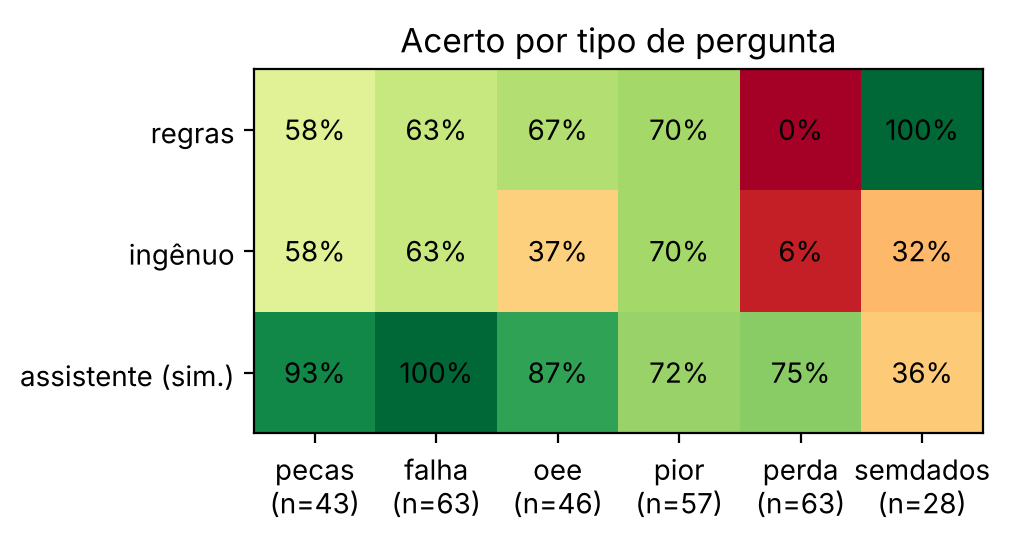

In [5]:
import numpy as np
tipos = ["pecas", "falha", "oee", "pior", "perda", "semdados"]
M = np.array([[np.mean([a for q, a in zip(qs, acertos[n]) if q.kind == t]) for t in tipos] for n in sistemas])
fig, ax = plt.subplots(figsize=(7.2, 2.8))
ax.imshow(M, cmap="RdYlGn", vmin=0, vmax=1)
ax.set_xticks(range(len(tipos)), [f"{t}\n(n={sum(q.kind == t for q in qs)})" for t in tipos]); ax.set_yticks(range(3), list(sistemas))
for i in range(3):
    for j in range(len(tipos)):
        ax.text(j, i, f"{M[i, j]:.0%}", ha="center", va="center")
ax.set_title("Acerto por tipo de pergunta"); plt.tight_layout()

A leitura por fatia muda a conclusão:

- **regras** é perfeita nas armadilhas e em tudo que entende, mas zera em `perda` (não sabe diagnosticar).
- **ingênuo** vai mal em `oee` e `semdados`: a média das médias e o hábito de nunca dizer "sem dados".
- **assistente** é o melhor geral, mas **só 36 % nas armadilhas**: inventa número em dois de cada três casos. Para um assistente que um supervisor vai usar, isso é o pior erro, porque parece uma resposta.

Medir só a média teria levado a escolher o assistente sem ver o risco.

Separando também pelo **jeito de perguntar** para as regras:

In [6]:
for t in range(3):
    sub = [a for q, a in zip(qs, acertos["regras"]) if q.template == t]
    print(f"jeito {t}: \"{TEXTS['oee'][t].format(m='prensa', d=9)}\"  -> regras acertam {np.mean(sub):.0%}")

jeito 0: "Qual foi o OEE da prensa no dia 9?"  -> regras acertam 78%
jeito 1: "Qual o OEE da prensa no dia 9, em porcentagem?"  -> regras acertam 81%
jeito 2: "OEE da prensa no 9º dia?"  -> regras acertam 9%


O terceiro jeito ("no 9º dia") quebra as regras: uma mudança de redação que uma pessoa nem percebe derruba o sistema. Um conjunto de avaliação com um só jeito de perguntar teria escondido isso. Se você tem logs de perguntas reais, use as frases reais.

## 4. Análise de erros

Um número de acerto diz **quanto** erra, não **por que**. Classifique os erros automaticamente em categorias e olhe exemplos:

ingênuo: Qual o maior fator de perda do OEE da paletizadora no dia 2: disponibilidade, desempenho ou qualidade?
   respondeu 'disponibilidade', gabarito 'desempenho'
assistente (sim.): Qual máquina teve o menor OEE no dia 3?
   respondeu 'prensa', gabarito 'enchedora'


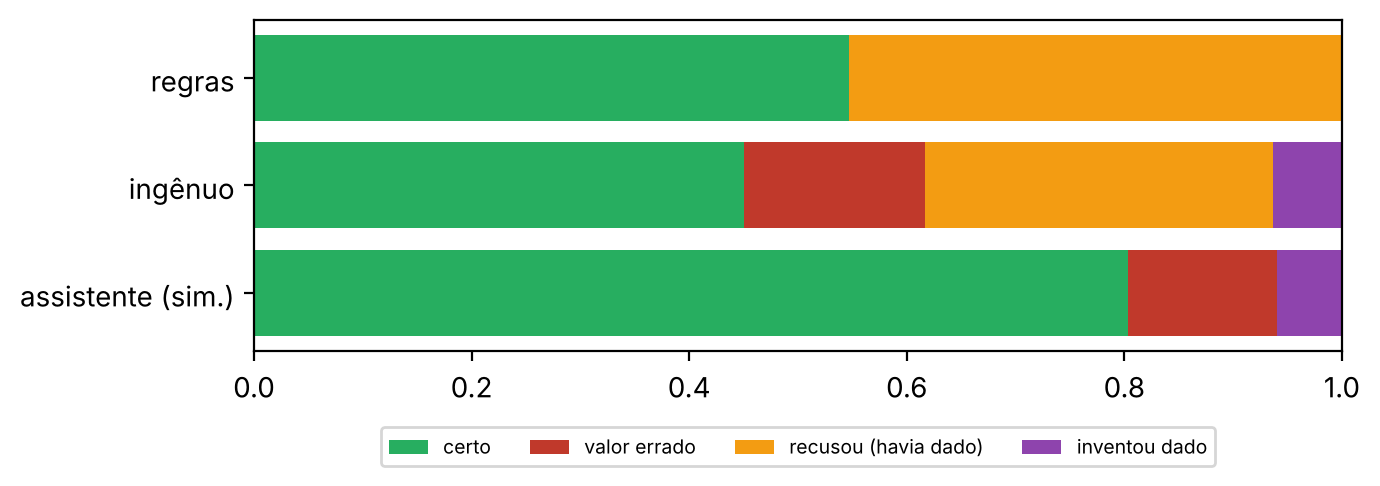

In [7]:
from aiind.oeeqa import ABSTAIN
def tipo_erro(q, resp):
    if correct(q, resp):
        return "certo"
    if any(x in resp.lower() for x in ABSTAIN):
        return "recusou (havia dado)"
    if q.gold == "sem dados":
        return "inventou dado"
    return "valor errado"
cats = ["certo", "valor errado", "recusou (havia dado)", "inventou dado"]
cont = {n: Counter(tipo_erro(q, r) for q, r in zip(qs, rs)) for n, rs in respostas.items()}
fig, ax = plt.subplots(figsize=(7, 2.6)); base = np.zeros(3)
for c, cor in zip(cats, ["#27ae60", "#c0392b", "#f39c12", "#8e44ad"]):
    v = np.array([cont[n][c] for n in sistemas]) / len(qs); ax.barh(list(sistemas), v, left=base, label=c, color=cor); base += v
ax.legend(ncol=4, fontsize=7, loc="upper center", bbox_to_anchor=(.5, -.2)); ax.invert_yaxis(); plt.tight_layout()
for nome in ["ingênuo", "assistente (sim.)"]:
    ex = next((q, r) for q, r in zip(qs, respostas[nome]) if tipo_erro(q, r) == "valor errado")
    print(f"{nome}: {ex[0].text}\n   respondeu {ex[1]!r}, gabarito {ex[0].gold!r}")

Cada barra diz algo diferente sobre o que consertar:

- **regras:** erro quase todo é "recusou": o remédio é cobrir mais frases e o diagnóstico.
- **ingênuo:** "valor errado" e "inventou dado": o remédio é corrigir o cálculo e a política de dado ausente.
- **assistente:** erros dispersos, e "inventou dado" nas armadilhas: o remédio é instrução e verificação, não mais dados.

Para o erro do ingênuo no OEE, o motivo é concreto: a média dos OEE dos turnos pesa igualmente um turno de 300 min e um de 480 min.

In [8]:
d = next(d for d in range(1, 15) if abs(factors(data, "prensa", d)["oee"] - np.mean([
    (r["run"]/r["planned"]) * (IDEAL["prensa"]*r["total"]/(r["run"]*60)) * ((r["total"]-r["defects"])/r["total"]) for r in data if r["machine"] == "prensa" and r["day"] == d])) > 0.005)
for r in [r for r in data if r["machine"] == "prensa" and r["day"] == d]:
    oee_turno = IDEAL["prensa"] * (r["total"] - r["defects"]) / (r["planned"] * 60)
    print(f"turno {r['shift']}: planejado {r['planned']} min, OEE do turno {oee_turno:.1%}")
print(f"\nOEE do dia 'média dos turnos' = {np.mean([IDEAL['prensa']*(r['total']-r['defects'])/(r['planned']*60) for r in data if r['machine']=='prensa' and r['day']==d]):.1%}")
print(f"OEE do dia ponderado pelo tempo = {factors(data, 'prensa', d)['oee']:.1%}")

turno 1: planejado 480 min, OEE do turno 86.9%
turno 2: planejado 300 min, OEE do turno 72.4%
turno 3: planejado 300 min, OEE do turno 56.1%

OEE do dia 'média dos turnos' = 71.8%
OEE do dia ponderado pelo tempo = 74.3%


A diferença passa da tolerância de 0,5 ponto, e é um erro que **parece certo**: ninguém desconfia de um número razoável. É por isso que o gabarito tem de vir de uma fonte independente (aqui, a fórmula correta aplicada aos dados brutos).

## 5. Quantas perguntas bastam?

Com 300 perguntas, "assistente 80 %" é um número, e uma conclusão é outra coisa. Um intervalo de confiança mostra o que as 300 perguntas permitem afirmar:

In [9]:
from aiind.oeeqa import wilson, paired_bootstrap
for nome in sistemas:
    k = sum(acertos[nome]); lo, hi = wilson(k, len(qs))
    print(f"{nome:18s} acerto {k/len(qs):.1%}   intervalo de 95 %: {lo:.1%} a {hi:.1%}")
dif, lo, hi = paired_bootstrap(acertos["regras"], acertos["ingênuo"])
print(f"\nregras menos ingênuo, nas mesmas perguntas: {dif:+.1%}  (intervalo {lo:+.1%} a {hi:+.1%})")

regras             acerto 54.7%   intervalo de 95 %: 49.0% a 60.2%
ingênuo            acerto 45.0%   intervalo de 95 %: 39.5% a 50.7%
assistente (sim.)  acerto 80.3%   intervalo de 95 %: 75.5% a 84.4%



regras menos ingênuo, nas mesmas perguntas: +9.7%  (intervalo +6.0% a +13.7%)


Os intervalos têm uns ±5 pontos, e os de regras (49 a 60 %) e ingênuo (40 a 51 %) **se sobrepõem**. Já a comparação **pareada**, nas mesmas perguntas, mostra uma diferença de ~10 pontos com intervalo de +6 a +14: separa, e por isso comparar sistemas nas mesmas perguntas é mais poderoso do que comparar dois intervalos soltos. Mesmo assim, é uma diferença pequena perto do que as fatias mostraram. Quantas perguntas seriam necessárias para ordenar dois sistemas parecidos? Simule: sorteie conjuntos de tamanho n de uma população grande e veja com que frequência o conjunto ordena os sistemas como a população.

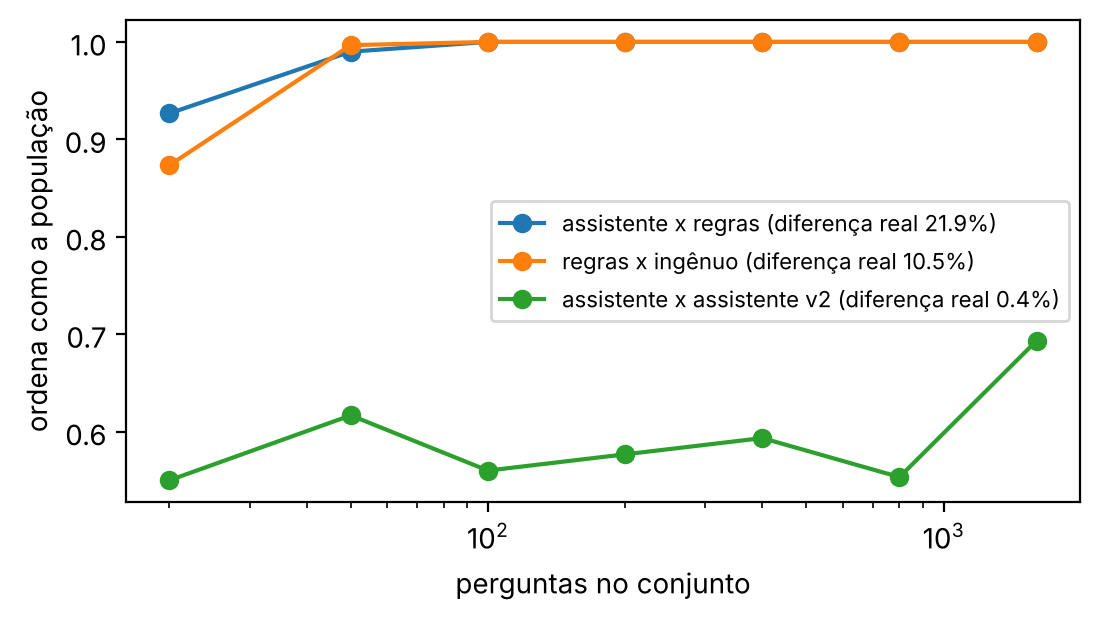

In [10]:
pop = build_questions(data, 3000, seed=99)
pa = {n: np.array([correct(q, f(q)) for q in pop]) for n, f in sistemas.items()}
pa["assistente v2 (sim.)"] = np.array([correct(q, assistente(data, q, seed=1)) for q in pop])   # outra versão, quase igual
rng = np.random.default_rng(0)
tamanhos = [20, 50, 100, 200, 400, 800, 1600]
pares = {"assistente x regras": ("assistente (sim.)", "regras"), "regras x ingênuo": ("regras", "ingênuo"),
         "assistente x assistente v2": ("assistente (sim.)", "assistente v2 (sim.)")}
fig, ax = plt.subplots(figsize=(5.6, 3.2))
for rotulo, (a, b) in pares.items():
    certo = pa[a].mean() > pa[b].mean()
    taxa = [np.mean([(pa[a][i].mean() > pa[b][i].mean()) == certo for i in (rng.choice(len(pop), n, replace=False) for _ in range(300))]) for n in tamanhos]
    ax.plot(tamanhos, taxa, "o-", label=f"{rotulo} (diferença real {abs(pa[a].mean()-pa[b].mean()):.1%})")
ax.set_xscale("log"); ax.set_xlabel("perguntas no conjunto"); ax.set_ylabel("ordena como a população"); ax.legend(fontsize=8); plt.tight_layout()

Diferenças de 10 a 20 pontos aparecem com 50 a 100 perguntas. Mas duas versões do assistente que diferem em **menos de 1 ponto** não são ordenadas de forma confiável nem com 1600 perguntas: a chance de acertar a ordem fica perto de uma moeda ao ar. Quanto menor a diferença que você quer detectar, mais perguntas precisa, e a conta cresce com o inverso do quadrado da diferença. Regra prática: se os intervalos se sobrepõem, a conclusão honesta é "não dá para separar", e a decisão passa a ser custo, risco e facilidade de manter. E quanto mais fatias você quer ler, mais perguntas precisa: 20 perguntas em cada fatia dão ±20 pontos.

## 6. Avaliar o próprio conjunto de avaliação

O conjunto também pode estar errado. Três verificações baratas:

**a) Vazamento por repetição.** Lembra dos 256 textos distintos entre 300? Se a mesma pergunta cai no conjunto de ajuste (onde você muda prompts e regras) e no de teste, quem ajustou **decorou** a resposta. Um sistema que só decora, dividindo ao acaso:

In [11]:
class Decorador:
    def __init__(self, ajuste):
        self.mem = {q.text: q.gold for q in ajuste}
    def __call__(self, q):
        return self.mem.get(q.text, "não sei")
def testar_decorador(qs_, dedup):
    pool = list({q.text: q for q in qs_}.values()) if dedup else list(qs_)
    r = random.Random(0); r.shuffle(pool)
    ajuste, teste = pool[:len(pool)//2], pool[len(pool)//2:]
    dec = Decorador(ajuste)
    return np.mean([correct(q, dec(q)) for q in teste])
print(f"decorador, divisão ao acaso:           {testar_decorador(qs, dedup=False):.0%} de acerto em 'teste'")
print(f"decorador, depois de tirar repetidas:  {testar_decorador(qs, dedup=True):.0%}")

decorador, divisão ao acaso:           22% de acerto em 'teste'
decorador, depois de tirar repetidas:  12%


Sem remover repetições, um sistema que **não entende nada** acerta quase o dobro (22 % contra 12 %, que são os pontos das armadilhas, onde "não sei" é a resposta certa). Regras: remova duplicatas **antes** de dividir, e divida por **cenário** (por exemplo por dia ou por máquina), não por pergunta, porque perguntas sobre o mesmo dia compartilham a resposta.

**b) Pisos.** Sistemas triviais mostram o piso do conjunto. Se "responder sempre 'não sei'" já dá uma nota alta, o conjunto está fácil demais ou desbalanceado:

In [12]:
triviais = {"sempre 'não sei'": lambda q: "não sei", "sempre 'sem dados'": lambda q: "sem dados", "sempre '0'": lambda q: "0"}
for n, f in triviais.items():
    print(f"{n:22s} {np.mean([correct(q, f(q)) for q in qs]):.0%}")

sempre 'não sei'       9%
sempre 'sem dados'     9%
sempre '0'             6%


O piso é baixo (a armadilha, 9 % das perguntas, dá os pontos do "sem dados"), então o conjunto discrimina. Esses números também ajudam a ler os outros: um sistema com 20 % não é "ruim por pouco", é do nível de quem chuta.

**c) Discriminação.** O conjunto serve se **separa** sistemas conhecidos como bons e ruins, por fatia. Na seção 3 ele separou: regras perfeitas onde entendem, ingênuo e assistente caindo em fatias diferentes. Se todos os sistemas tirassem 98 % em uma fatia, ela estaria **saturada** e não informaria mais nada. Aposente fatias saturadas e adicione perguntas mais difíceis.

## 7. Escolher: precisão, custo e combinação

A escolha não é só de acerto. Um modelo de linguagem recebe a tabela no prompt e gasta tokens; regras custam quase nada. Com preços **ilustrativos** (troque pelos reais do seu fornecedor): 800 tokens de entrada a US$ 1 por milhão e ~15 de saída a US$ 5 por milhão.

Há ainda uma terceira opção, comum na prática: **combinar**. Usar as regras primeiro e chamar o assistente **só quando as regras dizem "não sei"**:

sistema                 acerto  armadilha  custo por mil
regras                     55%       100%       US$ 0.00
ingênuo                    45%        32%       US$ 0.00
assistente (sim.)          80%        36%       US$ 0.88
regras + assistente        90%        75%       US$ 0.42


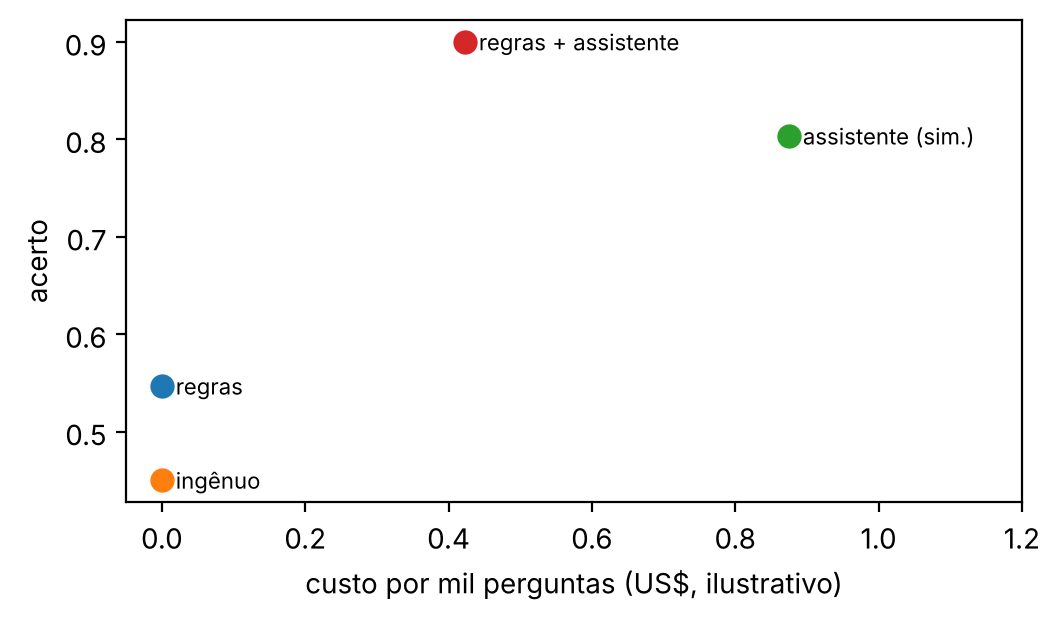

In [13]:
def hibrido(q):
    r = regras(data, q)
    return r if "não sei" not in r else assistente(data, q)
sistemas2 = {**sistemas, "regras + assistente": hibrido}
custo_chamada = (800 * 1.0 + 15 * 5.0) / 1e6          # US$ por chamada do assistente (ilustrativo)
chamadas = {"regras": 0, "ingênuo": 0, "assistente (sim.)": len(qs), "regras + assistente": sum("não sei" in regras(data, q) for q in qs)}
print(f"{'sistema':22s} {'acerto':>7s} {'armadilha':>10s} {'custo por mil':>14s}")
pts = {}
for n, f in sistemas2.items():
    rs = [f(q) for q in qs]; ac = np.mean([correct(q, r) for q, r in zip(qs, rs)])
    arm = np.mean([correct(q, r) for q, r in zip(qs, rs) if q.kind == "semdados"])
    custo = chamadas[n] / len(qs) * 1000 * custo_chamada; pts[n] = (custo, ac)
    print(f"{n:22s} {ac:7.0%} {arm:10.0%} {'US$ %.2f' % custo:>14s}")
fig, ax = plt.subplots(figsize=(5.4, 3.2))
for n, (c, a) in pts.items():
    ax.scatter(c, a, s=60); ax.annotate(n, (c, a), fontsize=8, xytext=(5, -3), textcoords="offset points")
ax.set_xlabel("custo por mil perguntas (US$, ilustrativo)"); ax.set_ylabel("acerto"); ax.set_xlim(-0.05, 1.2); plt.tight_layout()

A combinação **ganha do assistente sozinho em acerto, nas armadilhas e em custo**: as regras resolvem barato o que sabem (inclusive dizer "sem dados"), e o assistente fica para o que sobra. Mas as armadilhas ficaram em 75 %, abaixo do nosso mínimo de 90 %: quando uma pergunta sobre dia inexistente tem a redação que as regras não entendem, ela cai no assistente, que inventa. Conclusão do conjunto de avaliação, e tarefa para o capítulo 5: instruir e verificar o assistente para recusar quando não há dado. Esse padrão, **roteador** ou **cascata**, aparece em muitos sistemas de IA em produção.

**Sobre testes públicos (benchmarks).** Eles servem para fazer uma **lista curta** de modelos, não para decidir. Medem tarefas genéricas, e o seu conjunto mede a sua. Além disso, perguntas públicas podem ter vazado para o treino, e a conta de custo e latência é sempre sua. A decisão final sai do **seu** conjunto de avaliação.

## 8. Uma rotina que impede regressões

Um conjunto de avaliação só vale se for **rodado a cada mudança** (de modelo, prompt, regra ou dado). Uma rotina mínima: roda, compara por fatia com a versão anterior e **bloqueia** se alguma fatia piorar além de um limite ou ficar abaixo do mínimo.

In [14]:
def avaliar(f, qs_):
    out = {}
    for t in tipos:
        sub = [q for q in qs_ if q.kind == t]
        out[t] = np.mean([correct(q, f(q)) for q in sub])
    return out

def portao(antes, depois, queda_max=0.05, minimo={"semdados": 0.9}):
    problemas = []
    for t in tipos:
        if depois[t] < antes[t] - queda_max:
            problemas.append(f"{t}: caiu de {antes[t]:.0%} para {depois[t]:.0%}")
        if t in minimo and depois[t] < minimo[t]:
            problemas.append(f"{t}: {depois[t]:.0%} abaixo do mínimo de {minimo[t]:.0%}")
    return problemas

from aiind.oeeqa import parse, gold_for
def ingenuo_v2(q):                    # conserta o cálculo do OEE, mas esquece a armadilha
    p = parse(q.text)
    if p and p[0] in ("oee", "pior"):
        return gold_for(data, p[0], p[1], min(p[2], DAYS))
    return ingenuo(data, q)
antes, depois = avaliar(lambda q: ingenuo(data, q), qs), avaliar(ingenuo_v2, qs)
print(f"{'fatia':10s} {'v1':>5s} {'v2':>5s}")
for t in tipos:
    print(f"{t:10s} {antes[t]:5.0%} {depois[t]:5.0%}")
print("\nportão:", portao(antes, depois) or "liberado")

fatia         v1    v2
pecas        58%   58%
falha        63%   63%
oee          37%   67%
pior         70%   70%
perda         6%    6%
semdados     32%   32%

portão: ['semdados: 32% abaixo do mínimo de 90%']


A versão 2 melhorou o OEE (de 37 % para 67 %), mas continua **inventando dados** nos dias sem registro, e o portão bloqueia. Sem uma regra explícita sobre a fatia `semdados`, a melhoria média teria liberado a versão.

A rotina completa de um sistema real tem mais peças: o conjunto versionado, execução automática no CI, revisão humana de uma amostra, e um **ciclo de realimentação**: toda falha vista em produção vira uma pergunta nova no conjunto. É o que mantém a avaliação parecida com o uso de verdade.

## Erros comuns

- **Medir só a média.** Fatias contam a história (as armadilhas, os jeitos de perguntar).
- **Definir os limites depois de ver o resultado.**
- **Conjunto com um só jeito de perguntar.** Use frases reais de usuários.
- **Perguntas repetidas entre ajuste e teste.** Remova duplicatas e divida por cenário.
- **Gabarito que depende do próprio sistema avaliado.** Calcule-o de fonte independente.
- **Decidir por teste público.** Ele só ajuda a montar a lista curta.
- **Comparar sistemas sem intervalo.** Diferença menor que o ruído não é diferença.
- **Esquecer o custo.** O melhor sistema pode ser uma combinação mais barata.

## Confira o que ficou

**1. Por que o conjunto tem perguntas sobre dias que não existem?**

<details><summary>Ver resposta</summary>

Para medir se o sistema inventa dados. Sem armadilhas, um sistema que responde sempre um número parece ótimo.

</details>

**2. Por que o gabarito deste conjunto é calculado por código?**

<details><summary>Ver resposta</summary>

Porque o OEE tem fórmula exata. Não há discordância entre anotadores e dá para gerar milhares de perguntas.

</details>

**3. O assistente tem o maior acerto geral. Por que isso não basta para escolhê-lo?**

<details><summary>Ver resposta</summary>

A média esconde fatias: ele só acerta 36 % das armadilhas e inventa números. Importa também o custo e a combinação com regras.

</details>

**4. Dois sistemas têm 55 % e 45 % em 300 perguntas, com intervalos individuais que se sobrepõem. O que fazer?**

<details><summary>Ver resposta</summary>

Comparar nas mesmas perguntas com bootstrap pareado, que é mais poderoso. Se ainda for incerto, mais perguntas, olhar por fatia, ou decidir por custo e risco.

</details>

**5. Por que remover perguntas repetidas antes de dividir ajuste e teste?**

<details><summary>Ver resposta</summary>

Se a mesma pergunta está nos dois lados, o sistema pode decorar a resposta e o teste mede memória, não capacidade.

</details>

**6. O que é uma fatia saturada?**

<details><summary>Ver resposta</summary>

Uma fatia em que todos os sistemas já acertam quase tudo. Ela não discrimina mais e deve ser aposentada ou substituída por perguntas mais difíceis.

</details>

**7. Qual a vantagem de combinar regras e assistente?**

<details><summary>Ver resposta</summary>

As regras resolvem barato e com exatidão o que sabem, inclusive dizer 'sem dados'; o assistente só é chamado no resto, o que melhora acerto e custo.

</details>

## Exercícios

1. **Tolerância:** mude a tolerância do OEE de 0,5 para 3 pontos em `correct`. O ingênuo passa a ir bem? O que isso diz sobre escolher tolerâncias?
2. **Jeitos de perguntar:** acrescente um quarto jeito ("Como foi o OEE da {m} em {d}/03?") e veja o que acontece com as regras.
3. **Nova fatia:** crie o tipo `qualidade` ("qual a taxa de defeitos da {m} no dia {d}?") com gabarito calculado. Que sistemas acertam?
4. **Tamanho:** quantas perguntas são necessárias para separar `regras` e `ingênuo` em 95 % das amostras? Use a simulação da seção 5.
5. **Divisão por cenário:** divida ajuste e teste por **dia** (dias 1 a 7 e 8 a 14) em vez de por pergunta e refaça o teste do decorador.
6. **Custo:** com um modelo mais barato (metade do preço) mas 10 pontos menos de acerto, o gráfico da seção 7 muda de ordem?
7. **Portão:** acrescente ao portão o critério de formato (mínimo de 90 % de respostas só com o valor) e teste com o assistente.

## Glossário

- **Conjunto de avaliação:** perguntas com respostas conhecidas, usadas para medir o sistema.
- **Gabarito:** a resposta correta; aqui, calculada por código.
- **Armadilha:** pergunta cuja resposta certa é recusar ou dizer que não há dado.
- **Fatia:** subconjunto das perguntas (por tipo, jeito de perguntar, máquina) medido à parte.
- **Intervalo de confiança:** faixa plausível para o valor verdadeiro dado o tamanho da amostra.
- **Bootstrap pareado:** reamostrar as mesmas perguntas para ver a incerteza da diferença entre dois sistemas.
- **Vazamento:** informação de teste presente no ajuste ou no treino.
- **Saturação:** quando todos os sistemas já acertam quase tudo numa fatia.
- **Roteador / cascata:** sistema que escolhe quem responde (barato primeiro, caro só se preciso).
- **Portão de qualidade:** verificação automática que bloqueia uma versão que piora fatias ou fica abaixo do mínimo.

## Próximo passo

**Notebook 05, capítulo 5 (Prompt Engineering):** escrever, versionar e testar prompts para um assistente de chão de fábrica, com este conjunto de avaliação como teste de regressão, e medir ataques de injeção de prompt.